# Lineer Regression / Tips Linear Regression

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** No local CSV/XLSX next to this notebook; see code for in-library/remote datasets..  
**Methods referenced:** `LinearRegression`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


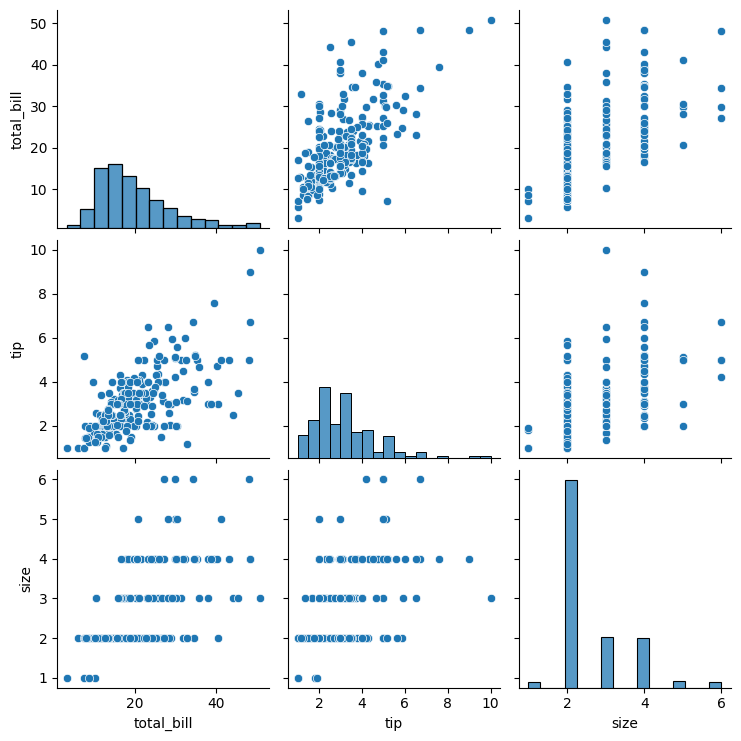

In [3]:
sns.pairplot(df)
plt.show()

In [4]:
df.corr(numeric_only = True)

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


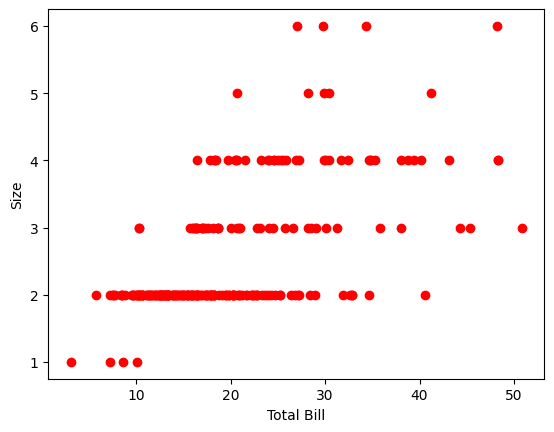

In [5]:
plt.scatter(df["total_bill"], df["size"], color = "r")
plt.xlabel("Total Bill")
plt.ylabel("Size")
plt.show()

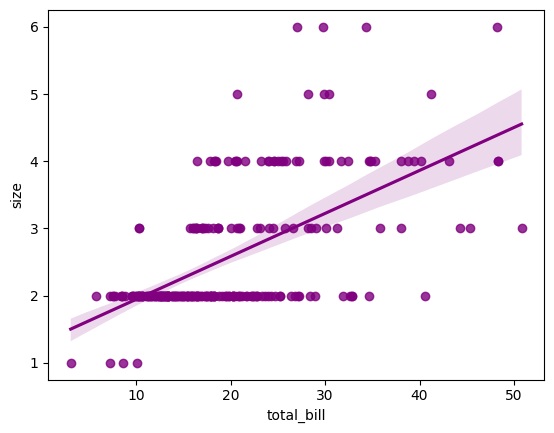

In [6]:
sns.regplot(x = df["total_bill"], y = df["size"], color = "purple")
plt.show()

### independent and dependent features

In [7]:
X = df["size"]
y = df["total_bill"]

In [8]:
X.head()

0    2
1    3
2    3
3    2
4    4
Name: size, dtype: int64

In [9]:
y.head()

0    16.99
1    10.34
2    21.01
3    23.68
4    24.59
Name: total_bill, dtype: float64

### train - test split

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 15)

In [12]:
from sklearn.preprocessing import StandardScaler

In [13]:
scaler = StandardScaler()

In [14]:
X_train = scaler.fit_transform(X_train.values.reshape(-1, 1))
X_test = scaler.transform(X_test.values.reshape(-1, 1))

In [15]:
X_train

array([[-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [ 0.37933712],
       [ 1.41543703],
       [-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [ 0.37933712],
       [-0.65676278],
       [ 0.37933712],
       [-0.65676278],
       [-0.65676278],
       [ 1.41543703],
       [ 0.37933712],
       [-0.65676278],
       [ 1.41543703],
       [-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [ 0.37933712],
       [ 2.45153693],
       [ 1.41543703],
       [-0.65676278],
       [ 0.37933712],
       [-0.65676278],
       [-0.65676278],
       [ 1.41543703],
       [ 1.41543703],
       [-0.65676278],
       [ 1.41543703],
       [-0.65676278],
       [ 0.37933712],
       [-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [-0.65676278],
       [ 0.37933712],
       [ 1.41543703],
       [ 0.37933712],
       [ 1.41543703],
       [-0.65676278],
       [ 1.41543703],
       [ 1

In [16]:
from sklearn.linear_model import LinearRegression

In [17]:
regression = LinearRegression()

In [18]:
regression.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [20]:
ten_size_scaled = scaler.transform([[10]])

In [21]:
real_prediction = regression.predict(ten_size_scaled)
print("real prediction: ", real_prediction)

real prediction:  [60.42824721]


### prediction

In [22]:
y_pred = regression.predict(X_test)

In [23]:
y_pred

array([16.57460187, 11.0928962 , 16.57460187, 16.57460187, 27.53801321,
       27.53801321, 16.57460187, 16.57460187, 16.57460187, 16.57460187,
       22.05630754, 27.53801321, 16.57460187, 16.57460187, 22.05630754,
       16.57460187, 16.57460187, 27.53801321, 16.57460187, 33.01971887,
       16.57460187, 16.57460187, 27.53801321, 16.57460187, 16.57460187,
       16.57460187, 16.57460187, 16.57460187, 11.0928962 , 16.57460187,
       16.57460187, 16.57460187, 22.05630754, 16.57460187, 22.05630754,
       16.57460187, 22.05630754, 16.57460187, 16.57460187, 38.50142454,
       16.57460187, 16.57460187, 16.57460187, 16.57460187, 22.05630754,
       16.57460187, 16.57460187, 16.57460187, 16.57460187, 16.57460187,
       16.57460187, 16.57460187, 22.05630754, 16.57460187, 16.57460187,
       16.57460187, 16.57460187, 16.57460187, 16.57460187, 16.57460187,
       22.05630754])

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [25]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("mse: ", mse)
print("mae: ", mae)

mse:  41.919656811228805
mae:  4.7831957596497245


In [26]:
score = r2_score(y_test, y_pred)
print("r2 score: ", score)

r2 score:  0.40156863672995413


In [27]:
regression.intercept_

np.float64(20.04934426229508)

In [28]:
print(regression.coef_)

[5.29071149]


In [29]:
1 - (1 - score) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

0.39142573226775